# Training the detector on IBM LinuxONE: XGBoost on PaySim

This notebook trains ShieldZ's fraud detector from scratch on the full PaySim dataset, on the LinuxONE VM (s390x), and evaluates it. It calls the same code the project uses (`shieldz.model`), then plots the results.

It works in a scratch folder. It does **not** overwrite the deployed model, the deployed thresholds, or the committed model card.

1. The data: how rare fraud is, and where it happens
2. A time-based split (train on the past, test on the future)
3. Training XGBoost on s390x
4. How good is it? Curves, scores and the confusion matrix
5. Which features matter, and why a decision comes with reason codes
6. Does the model beat simple rules and tiny decision trees?
7. Thresholds: a correction about how they were chosen

In [1]:
import gc, json, os, platform, sys, tempfile, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (7, 3.4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "shieldz").exists())
sys.path[:0] = [str(REPO / "src")]
WORK = Path(tempfile.mkdtemp(prefix="shieldz_train_"))
os.environ["SHIELDZ_ARTIFACTS"] = str(WORK)   # nothing deployed is touched

def meminfo():
    kb = {l.split(":")[0]: int(l.split()[1]) for l in open("/proc/meminfo")}
    return kb["MemTotal"] / 1e6, kb["MemAvailable"] / 1e6

total, free = meminfo()
print("Machine architecture :", platform.machine())
print("CPU cores visible    :", os.cpu_count())
print(f"Memory               : {total:.1f} GB total, {free:.1f} GB available")
import xgboost, sklearn
print("xgboost / scikit-learn / numpy / pandas:", xgboost.__version__, "/", sklearn.__version__, "/", np.__version__, "/", pd.__version__)

Machine architecture : s390x
CPU cores visible    : 3
Memory               : 8.2 GB total, 5.4 GB available


xgboost / scikit-learn / numpy / pandas: 3.4.1 / 1.9.0 / 2.0.2 / 3.0.6


## 1. The data

PaySim is a public, **synthetic** dataset of mobile-money transactions (about 6.4 million rows over 30 days). We use only what a bank knows *before* a payment executes. The columns that describe the balances *after* the payment are never loaded, because they would leak the answer.

In [2]:
from shieldz.model.data import default_data_path, get_peak_rss_mb, load_paysim

NROWS = int(os.environ.get("SHIELDZ_NB_ROWS", "0")) or None   # a quick debug run; the real run is the full file
t0 = time.time()
X, y, step = load_paysim(nrows=NROWS)
load_s = time.time() - t0
print("Data file          :", default_data_path().name)
print(f"Rows loaded        : {len(X):,} in {load_s:.1f} s (peak memory {get_peak_rss_mb():,.0f} MB)")
print(f"Fraud rows         : {int(y.sum()):,}  ({y.mean() * 100:.3f}% of all rows)")
print("Features per row   :", X.shape[1])
X.head(3)

Data file          : paysim1.csv.gz
Rows loaded        : 6,362,620 in 16.2 s (peak memory 3,964 MB)
Fraud rows         : 8,213  (0.129% of all rows)
Features per row   : 12


,type_TRANSFER,type_CASH_OUT,type_PAYMENT,type_CASH_IN,type_DEBIT,log_amount,amount_to_balance,drains_account,payee_is_merchant,payee_prior_inbound,payee_balance_before_zero,hour_of_day
0,0,0,1,0,0,9.194276,0.057834,0,1,0,0,1
1,0,0,1,0,0,7.531166,0.087731,0,1,0,0,1
2,1,0,0,0,0,5.204007,0.994505,1,0,0,1,1


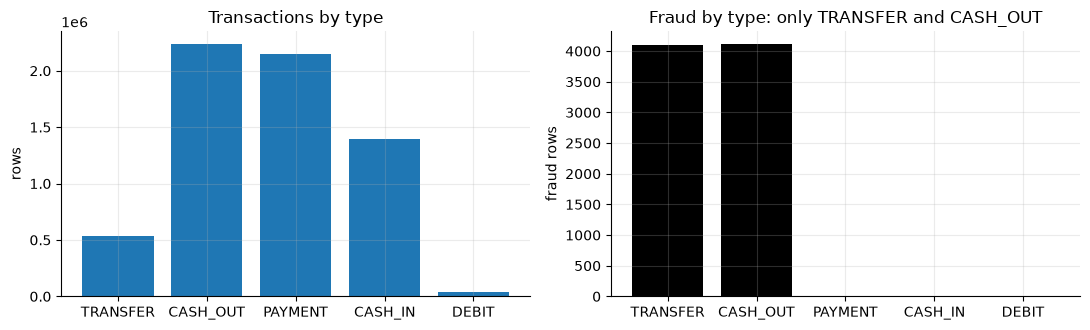

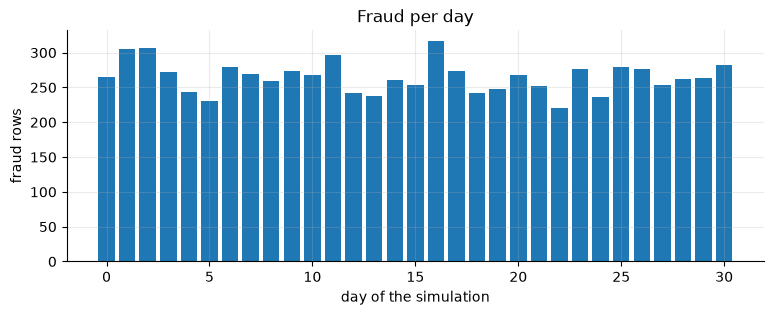

In [3]:
type_cols = [c for c in X.columns if c.startswith("type_")]
kind = X[type_cols].to_numpy().argmax(axis=1)
names = [c.replace("type_", "") for c in type_cols]
rows = np.bincount(kind, minlength=len(names))
fraud = np.bincount(kind, weights=y.to_numpy(), minlength=len(names)).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(names, rows)
axes[0].set_title("Transactions by type"); axes[0].set_ylabel("rows")
axes[1].bar(names, fraud, color="black")
axes[1].set_title("Fraud by type: only TRANSFER and CASH_OUT"); axes[1].set_ylabel("fraud rows")
plt.tight_layout(); plt.show()

day = (step.to_numpy() // 24)
per_day = np.bincount(day, weights=y.to_numpy()).astype(int)
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(per_day)), per_day)
ax.set_xlabel("day of the simulation"); ax.set_ylabel("fraud rows"); ax.set_title("Fraud per day")
plt.show()

## 2. A time-based split

Fraud detection is used on tomorrow's payments, so we train on the past and test on the future. A random split would let the model see payments from the same days it is tested on. Steps are hours: steps up to 500 train, 500 to 600 choose settings, and everything after 600 is the untouched test set.

In [4]:
s_max = int(step.max())
VAL_FROM, TEST_FROM = (500, 600) if s_max > 600 else (int(s_max * 0.70), int(s_max * 0.85))   # smaller debug runs
train_mask = (step <= VAL_FROM).to_numpy()
val_mask = ((step > VAL_FROM) & (step <= TEST_FROM)).to_numpy()
test_mask = (step > TEST_FROM).to_numpy()
X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]
del X, y, step, kind, day
gc.collect()
pd.DataFrame({"split": ["train", "validation", "test"],
              "steps": [f"1 to {VAL_FROM}", f"{VAL_FROM + 1} to {TEST_FROM}", f"after {TEST_FROM}"],
              "rows": [len(X_train), len(X_val), len(X_test)],
              "fraud": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())]})

,split,steps,rows,fraud
0,train,1 to 500,6061807,5561
1,validation,501 to 600,197240,1052
2,test,after 600,103573,1600


## 3. Training XGBoost on s390x

Gradient-boosted trees, histogram method, with the fraud class weighted up (fraud is about 0.13% of rows). Training stops early when the validation score stops improving. The output below shows the score every 10 rounds.

In [5]:
from shieldz.model.train import train_xgboost

t0 = time.time()
booster = train_xgboost(X_train, y_train, X_val=X_val, y_val=y_val)
train_s = time.time() - t0
print(f"\nTrained in {train_s:.0f} s on {os.cpu_count()} cores | trees: {booster.num_boosted_rounds()} | best round: {booster.best_iteration}")

[0]	train-aucpr:0.77509	train-auc:0.99957	val-aucpr:0.95588	val-auc:0.99981


[10]	train-aucpr:0.94765	train-auc:0.99985	val-aucpr:0.98799	val-auc:0.99994


[20]	train-aucpr:0.95179	train-auc:0.99982	val-aucpr:0.98815	val-auc:0.99994


[28]	train-aucpr:0.95201	train-auc:0.99991	val-aucpr:0.98883	val-auc:0.99994



Trained in 19 s on 3 cores | trees: 29 | best round: 13


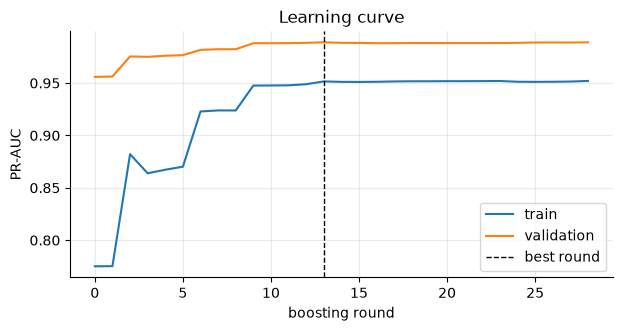

In [6]:
hist = booster.evals_result_
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(hist["train"]["aucpr"], label="train")
ax.plot(hist["val"]["aucpr"], label="validation")
ax.axvline(booster.best_iteration, color="black", linestyle="--", linewidth=1, label="best round")
ax.set_xlabel("boosting round"); ax.set_ylabel("PR-AUC"); ax.set_title("Learning curve"); ax.legend()
plt.show()

## 4. How good is it?

All numbers in this section are measured on the **test** split, which the model never saw. PR-AUC (area under the precision-recall curve) is the right headline for rare events. The best possible value is 1.0 and the baseline for random guessing is the fraud rate.

In [7]:
import xgboost as xgb
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from shieldz.contracts import FEATURE_ORDER
from shieldz.model.evaluate import recall_at_fpr, select_thresholds

cols = list(FEATURE_ORDER)
def predict(frame):
    return booster.predict(xgb.DMatrix(frame[cols], feature_names=cols))

p_val, p_test = predict(X_val), predict(X_test)
yt, yv = y_test.to_numpy(), y_val.to_numpy()
pr_auc, roc_auc = average_precision_score(yt, p_test), roc_auc_score(yt, p_test)
rec1 = recall_at_fpr(yt, p_test, 0.01)

stored = json.loads((REPO / "results" / "model_metrics.json").read_text())
pd.DataFrame([
    ["PR-AUC", round(pr_auc, 4), stored["pr_auc"]],
    ["ROC-AUC", round(roc_auc, 4), stored["roc_auc"]],
    ["Recall at 1% false alarms", round(rec1, 4), stored["recall_at_1pct_fpr"]],
    ["Fraud rate (what random guessing scores)", round(yt.mean(), 4), "-"],
], columns=["metric", "this run (just trained)", "deployed model card"])

,metric,this run (just trained),deployed model card
0,PR-AUC,0.9944,0.9944
1,ROC-AUC,0.9999,0.9999
2,Recall at 1% false alarms,0.9994,0.9994
3,Fraud rate (what random guessing scores),0.0154,-


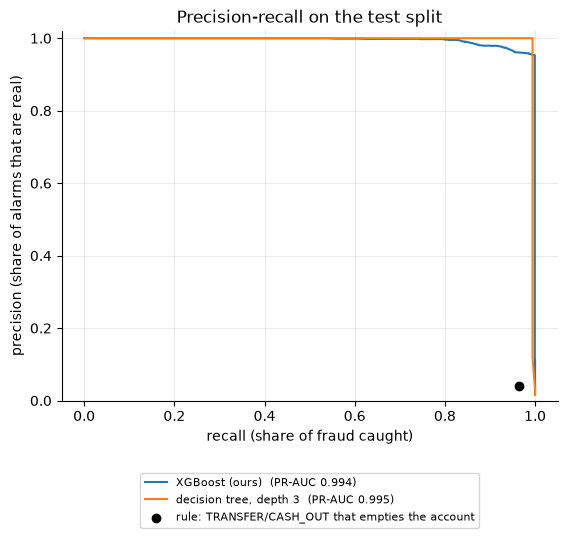

In [8]:
# Precision-recall curves: the model, a depth-3 decision tree, and the obvious hand-written rule
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=0).fit(X_train[cols], y_train)
p_tree = tree.predict_proba(X_test[cols])[:, 1]
risky = ((X_test["type_TRANSFER"] == 1) | (X_test["type_CASH_OUT"] == 1)).to_numpy()
rule = risky & (X_test["drains_account"] == 1).to_numpy()
rule_p, rule_r = (rule & (yt == 1)).sum() / max(rule.sum(), 1), (rule & (yt == 1)).sum() / yt.sum()

fig, ax = plt.subplots(figsize=(6.4, 4.8))
for label, p in (("XGBoost (ours)", p_test), ("decision tree, depth 3", p_tree)):
    prec, rec, _ = precision_recall_curve(yt, p)
    ax.plot(rec, prec, label=f"{label}  (PR-AUC {average_precision_score(yt, p):.3f})")
ax.scatter([rule_r], [rule_p], color="black", zorder=5, label="rule: TRANSFER/CASH_OUT that empties the account")
ax.set_xlabel("recall (share of fraud caught)"); ax.set_ylabel("precision (share of alarms that are real)")
ax.set_ylim(0, 1.02); ax.set_title("Precision-recall on the test split")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=8)
plt.show()

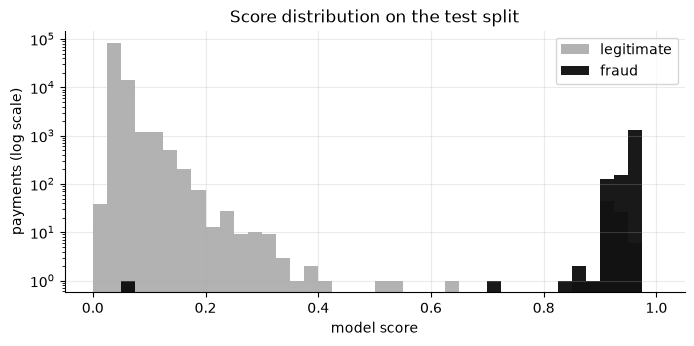

In [9]:
# What the scores look like: fraud and legitimate payments are almost perfectly separated
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 1, 41)
ax.hist(p_test[yt == 0], bins=bins, alpha=0.6, label="legitimate", color="gray")
ax.hist(p_test[yt == 1], bins=bins, alpha=0.9, label="fraud", color="black")
ax.set_yscale("log"); ax.set_xlabel("model score"); ax.set_ylabel("payments (log scale)")
ax.set_title("Score distribution on the test split"); ax.legend()
plt.show()

## 5. Which features matter, and where reason codes come from

The model uses 12 numbers per payment. The bar chart shows how much each one contributes (by "gain", the improvement each feature's splits bring). For every blocked or reviewed payment, XGBoost's exact feature contributions (TreeSHAP) are turned into at most three reason codes from a fixed list, with no raw numbers.

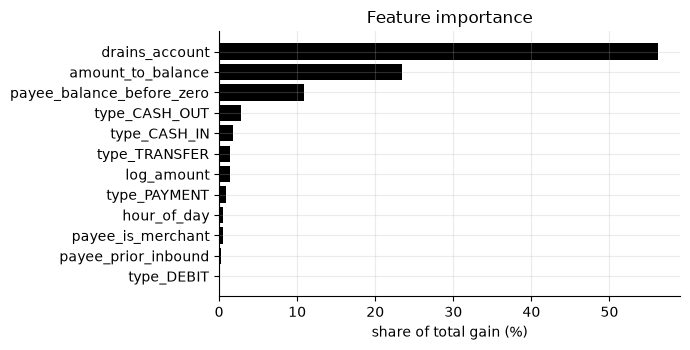

In [10]:
gain = pd.Series(booster.get_score(importance_type="gain")).sort_values()
share = gain / gain.sum()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(share.index, share.values * 100, color="black")
ax.set_xlabel("share of total gain (%)"); ax.set_title("Feature importance")
plt.tight_layout(); plt.show()

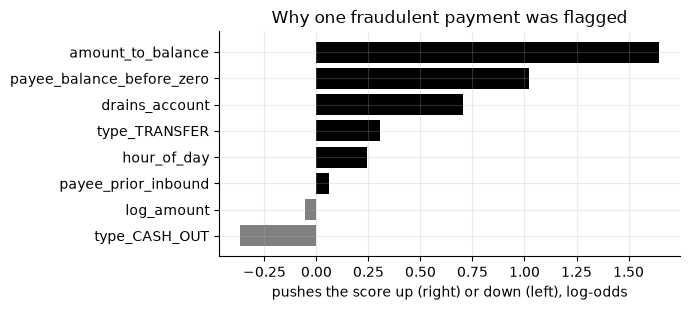

model score: 0.973
reason codes returned: [('AMOUNT_HIGH_VS_BALANCE', 'HIGH'), ('MULE_ACCOUNT_PATTERN', 'HIGH'), ('ACCOUNT_DRAIN', 'HIGH')]


In [11]:
# One flagged payment: its feature contributions, and the reason codes the service would return
from shieldz.contracts import FeatureVector
from shieldz.model.engine import XGBoostEngine

engine = XGBoostEngine(booster)
confident = np.where((yt == 1) & (p_test > 0.9))[0]
flagged = int(confident[0]) if len(confident) else int(np.argmax(np.where(yt == 1, p_test, -1)))
row = X_test.iloc[flagged]
contribs = booster.predict(xgb.DMatrix(X_test.iloc[[flagged]][cols], feature_names=cols), pred_contribs=True)[0][:-1]
top = pd.Series(contribs, index=cols).sort_values()
top = top[top.abs() > 0.05]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(top.index, top.values, color=["black" if v > 0 else "gray" for v in top.values])
ax.set_xlabel("pushes the score up (right) or down (left), log-odds"); ax.set_title("Why one fraudulent payment was flagged")
plt.tight_layout(); plt.show()

features = FeatureVector(**{c: (float(row[c]) if isinstance(row[c], (float, np.floating)) else int(row[c])) for c in cols})
print(f"model score: {engine.score(features):.3f}")
print("reason codes returned:", [(code.value, level.value) for code, level in engine.reasons(features)])

## 6. Does the model beat simple rules and tiny decision trees?

An honest check. PaySim fraud is mostly "the account was emptied", so a very small model can do well. We compare at each detector's natural operating point.

,detector,fraud caught,recall,false alarms,precision
0,rule: TRANSFER/CASH_OUT that empties the account,1542 of 1600,0.9638,37063,0.040
1,"decision tree, depth 2",1542 of 1600,0.9638,1,0.999
2,"decision tree, depth 3",1591 of 1600,0.9944,5,0.997
3,"decision tree, depth 4",1599 of 1600,0.9994,4,0.998
4,"XGBoost (ours), block at 0.9182",1524 of 1600,0.9525,56,0.965


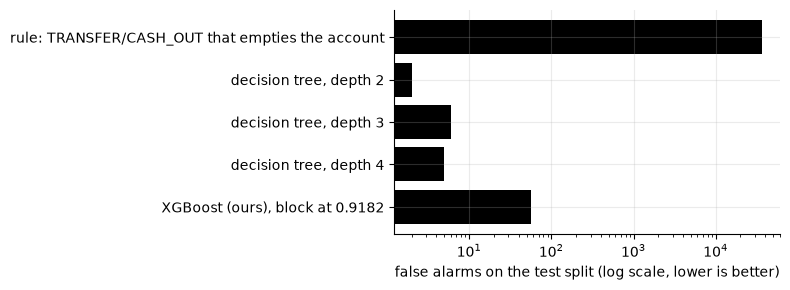

In [12]:
t_review_v, t_block_v = select_thresholds(yv, p_val)   # chosen on the VALIDATION split (section 7)

def line(name, flag):
    flag = np.asarray(flag).astype(bool)
    tp, fp = int((flag & (yt == 1)).sum()), int((flag & (yt == 0)).sum())
    return {"detector": name, "fraud caught": f"{tp} of {int(yt.sum())}", "recall": round(tp / yt.sum(), 4),
            "false alarms": fp, "precision": round(tp / max(tp + fp, 1), 3)}

trees = {d: DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=0).fit(X_train[cols], y_train)
         for d in (2, 3, 4)}
table = [line("rule: TRANSFER/CASH_OUT that empties the account", rule)]
table += [line(f"decision tree, depth {d}", t.predict_proba(X_test[cols])[:, 1] >= 0.5) for d, t in trees.items()]
table += [line(f"XGBoost (ours), block at {t_block_v}", p_test >= t_block_v)]
compare = pd.DataFrame(table)
display(compare)

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(compare["detector"], compare["false alarms"] + 1, color="black")
ax.set_xscale("log"); ax.set_xlabel("false alarms on the test split (log scale, lower is better)")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

**Reading it.** The obvious hand-written rule raises thousands of false alarms, because many legitimate PaySim payments also empty an account. A learned decision tree of depth 3 matches the model. So the detector is not where ShieldZ's value is: PaySim fraud is close to a threshold pattern. The contribution of this project is the pipeline around the model (the privacy barrier, the leak audit, the signed audit trail, and real-time decisions on the same platform as the data).

## 7. Thresholds: a correction about how they were chosen

A payment is BLOCKed above one score and held for REVIEW above a lower one. Those two thresholds must be chosen on data that is **not** the test split, otherwise the test results flatter the model.

The deployed thresholds were selected in `evaluate_model` from the **test** split's scores, not the validation split's. The headline metrics (PR-AUC, ROC-AUC, recall at 1% false alarms) do not use thresholds and are unaffected. The confusion matrix in the model card does, so it is slightly optimistic. Below, thresholds are chosen on the validation split, the correct way, and the test confusion matrix is recomputed.

In [13]:
thresholds_file = REPO / "artifacts" / "model" / "thresholds.json"
deployed = json.loads(thresholds_file.read_text()) if thresholds_file.exists() else {"t_review": float("nan"), "t_block": float("nan")}

def confusion(p, y_true, t_review, t_block):
    decision = np.where(p >= t_block, "BLOCK", np.where(p >= t_review, "REVIEW", "ALLOW"))
    return {f"{who} {d.lower()}": int(((decision == d) & ((y_true == 1) == (who == "fraud"))).sum())
            for who in ("fraud", "legit") for d in ("ALLOW", "REVIEW", "BLOCK")}

compare_thresholds = pd.DataFrame([
    {"thresholds": "deployed (picked on the test split)", "review at": deployed["t_review"], "block at": deployed["t_block"],
     **confusion(p_test, yt, deployed["t_review"], deployed["t_block"])},
    {"thresholds": "picked on the validation split", "review at": t_review_v, "block at": t_block_v,
     **confusion(p_test, yt, t_review_v, t_block_v)},
])
compare_thresholds

,thresholds,review at,block at,fraud allow,fraud review,fraud block,legit allow,legit review,legit block
0,deployed (picked on the test split),0.7,0.7500,1,1,1598,101894,0,79
1,picked on the validation split,0.7,0.9182,1,75,1524,101894,23,56


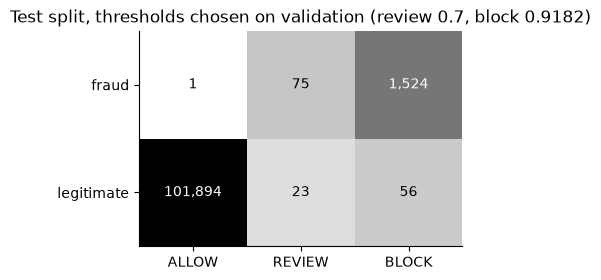

In [14]:
# The confusion matrix at the validation-chosen thresholds, as a picture
c = confusion(p_test, yt, t_review_v, t_block_v)
grid = np.array([[c["fraud allow"], c["fraud review"], c["fraud block"]],
                 [c["legit allow"], c["legit review"], c["legit block"]]])
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.imshow(np.log1p(grid), cmap="Greys")
ax.set_xticks(range(3), ["ALLOW", "REVIEW", "BLOCK"]); ax.set_yticks(range(2), ["fraud", "legitimate"]); ax.grid(False)
for i in range(2):
    for j in range(3):
        ax.text(j, i, f"{grid[i, j]:,}", ha="center", va="center",
                color="white" if np.log1p(grid[i, j]) > np.log1p(grid).max() / 2 else "black")
ax.set_title(f"Test split, thresholds chosen on validation (review {t_review_v}, block {t_block_v})")
plt.show()

## What this shows, and what it does not

**It shows** that the full PaySim dataset loads and trains on LinuxONE in minutes, that the model separates fraud from legitimate payments almost perfectly on a time-based test, and where its decisions and reason codes come from.

**It does not show** accuracy on real fraud or on elderly users: the data is synthetic and has no demographics. A depth-3 decision tree matches the model, so a high score here says more about PaySim than about the model. The model's strongest signals are PaySim artefacts: an account being emptied exactly, and a zero balance at the receiving account. A large partial transfer to a stranger scores low, which is why the service adds a policy rule next to the model.

In [15]:
import shutil
shutil.rmtree(WORK, ignore_errors=True)
print("scratch folder removed; the deployed model was not touched")

scratch folder removed; the deployed model was not touched
